# Uji Canny untuk kompleksitas latar

Pertanyaan: apakah edge density Canny di pinggir foto bisa membedakan latar polos dan ramai pada data kita?

Kriteria lulus ditetapkan sebelum melihat hasil: AUC ≥ 0,90 dan agreement ≥ 85%. Kalau tidak lulus, latar dilabeli manual dan Canny dilaporkan sebagai metode yang dicoba.

## Bagian 1: Menyiapkan pelabelan

Sel di bagian ini memilih 40 foto, membuat lembar foto bernomor, dan menyiapkan CSV label. Skor Canny sengaja belum dihitung supaya penilaian visual tidak terpengaruh.

In [21]:
import cv2
import numpy as np
import pandas as pd

from core.config import DATA_DIR, LOG_SOURCES, REPORTS_DIR, ROOT
from core.image import load_image
from dataset.acquisition import read_log, to_photo_table

photos = to_photo_table(read_log(LOG_SOURCES[0]))
photos = photos[photos["raw_path"].map(lambda path: (DATA_DIR / path).exists())]
photos.groupby("label")["object_id"].nunique()

label
kardus     34
kertas     27
plastik    38
Name: object_id, dtype: int64

In [22]:
SEED = 42
PAIRS_PER_CLASS = 3
SINGLES_PER_CLASS = {"plastik": 8, "kertas": 7, "kardus": 7}
LABELS_CSV = ROOT / "dataset" / "labels" / "background_sample.csv"


def sample_photos(photos: pd.DataFrame, rng: np.random.Generator) -> pd.DataFrame:
    """Pilih foto per kelas: beberapa objek diambil atas dan miring, sisanya satu foto acak."""
    chosen = []
    for label, singles in SINGLES_PER_CLASS.items():
        objects = np.sort(photos.loc[photos["label"] == label, "object_id"].unique())
        picked = rng.choice(objects, size=PAIRS_PER_CLASS + singles, replace=False)
        for object_id in picked[:PAIRS_PER_CLASS]:
            chosen += [(object_id, "atas"), (object_id, "miring")]
        for object_id in picked[PAIRS_PER_CLASS:]:
            chosen.append((object_id, str(rng.choice(["atas", "miring"]))))
    keys = pd.DataFrame(chosen, columns=["object_id", "view"])
    return keys.merge(photos, on=["object_id", "view"]).sample(frac=1, random_state=SEED)


if LABELS_CSV.exists():
    sample = pd.read_csv(LABELS_CSV, dtype=str, keep_default_na=False)
    print("Memakai sampel yang sudah ada:", LABELS_CSV.relative_to(ROOT))
else:
    picked = sample_photos(photos, np.random.default_rng(SEED))
    sample = pd.DataFrame({"no": range(1, len(picked) + 1), "raw_path": picked["raw_path"].to_numpy(), "background": ""})
    LABELS_CSV.parent.mkdir(parents=True, exist_ok=True)
    sample.to_csv(LABELS_CSV, index=False)
    print("Sampel baru disimpan:", LABELS_CSV.relative_to(ROOT))

sample.merge(photos[["raw_path", "label", "view"]], on="raw_path").groupby(["label", "view"]).size().unstack()

Memakai sampel yang sudah ada: dataset\labels\background_sample.csv


view,atas,miring
label,,
kardus,6,7
kertas,7,6
plastik,6,8


In [23]:
THUMB = 400
COLUMNS = 5
PER_SHEET = 10


def thumbnail(raw_path: str, number) -> np.ndarray:
    """Foto diperkecil ke kotak THUMB x THUMB dengan nomor di pojok kiri atas."""
    image = load_image(DATA_DIR / raw_path)
    height, width = image.shape[:2]
    scale = THUMB / max(height, width)
    image = cv2.resize(image, (round(width * scale), round(height * scale)), interpolation=cv2.INTER_AREA)
    canvas = np.full((THUMB, THUMB, 3), 255, np.uint8)
    top, left = (THUMB - image.shape[0]) // 2, (THUMB - image.shape[1]) // 2
    canvas[top : top + image.shape[0], left : left + image.shape[1]] = image
    cv2.rectangle(canvas, (0, 0), (80, 56), (255, 255, 255), -1)
    cv2.putText(canvas, str(number), (8, 44), cv2.FONT_HERSHEY_SIMPLEX, 1.5, (0, 0, 0), 3)
    return cv2.copyMakeBorder(canvas, 4, 4, 4, 4, cv2.BORDER_CONSTANT, value=(180, 180, 180))


def contact_sheet(tiles: list[np.ndarray], columns: int) -> np.ndarray:
    """Susun potongan foto menjadi grid; sisa slot diisi kotak putih."""
    tiles = tiles + [np.full_like(tiles[0], 255)] * (-len(tiles) % columns)
    rows = [np.hstack(tiles[i : i + columns]) for i in range(0, len(tiles), columns)]
    return np.vstack(rows)


sheet_dir = REPORTS_DIR / "dataset"
sheet_dir.mkdir(parents=True, exist_ok=True)
for start in range(0, len(sample), PER_SHEET):
    part = sample.iloc[start : start + PER_SHEET]
    sheet = contact_sheet([thumbnail(p, n) for p, n in zip(part["raw_path"], part["no"])], COLUMNS)
    path = sheet_dir / f"background_sheet_{start // PER_SHEET + 1}.png"
    path.write_bytes(cv2.imencode(".png", sheet)[1].tobytes())
    print("disimpan:", path.relative_to(ROOT))

disimpan: reports\dataset\background_sheet_1.png
disimpan: reports\dataset\background_sheet_2.png
disimpan: reports\dataset\background_sheet_3.png
disimpan: reports\dataset\background_sheet_4.png


### Cara melabeli

1. Buka `reports/dataset/background_sheet_1.png` sampai `background_sheet_4.png`.
2. Isi kolom `background` di `dataset/labels/background_sample.csv` untuk setiap nomor.
3. Label mengikuti aturan di `docs/panduan-label-latar.md`.

Bagian 2 baru dijalankan setelah semua label terisi.

## Bagian 2: Menguji Canny

Parameter dikunci sebelum melihat hasil dan tidak diubah setelahnya: ukuran analisis 512 px, Gaussian blur 5×5, ambang Canny (0,5 × Otsu, Otsu), dan pita pinggir 10%.

In [24]:
ANALYSIS_SIZE = 512
BLUR_KERNEL = (5, 5)
BORDER = 0.10


def border_mask(shape: tuple[int, int], border: float) -> np.ndarray:
    """Mask boolean yang bernilai True di pita pinggir selebar `border` dari setiap sisi."""
    height, width = shape
    dy, dx = round(height * border), round(width * border)
    mask = np.ones(shape, bool)
    mask[dy : height - dy, dx : width - dx] = False
    return mask


def canny_steps(raw_path: str) -> dict:
    """Semua tahap pengukuran latar untuk satu foto, dipakai untuk skor dan visualisasi."""
    image = load_image(DATA_DIR / raw_path)
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    scale = ANALYSIS_SIZE / max(gray.shape)
    gray = cv2.resize(gray, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
    blurred = cv2.GaussianBlur(gray, BLUR_KERNEL, 0)
    otsu, _ = cv2.threshold(blurred, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    edges = cv2.Canny(blurred, 0.5 * otsu, otsu)
    band = border_mask(edges.shape, BORDER)
    return {"image": image, "gray": gray, "blurred": blurred, "otsu": otsu, "edges": edges, "band": band}


def edge_density(raw_path: str) -> float:
    """Proporsi piksel tepi Canny di pita pinggir foto, dari 0 sampai 1."""
    steps = canny_steps(raw_path)
    return float((steps["edges"][steps["band"]] > 0).mean())

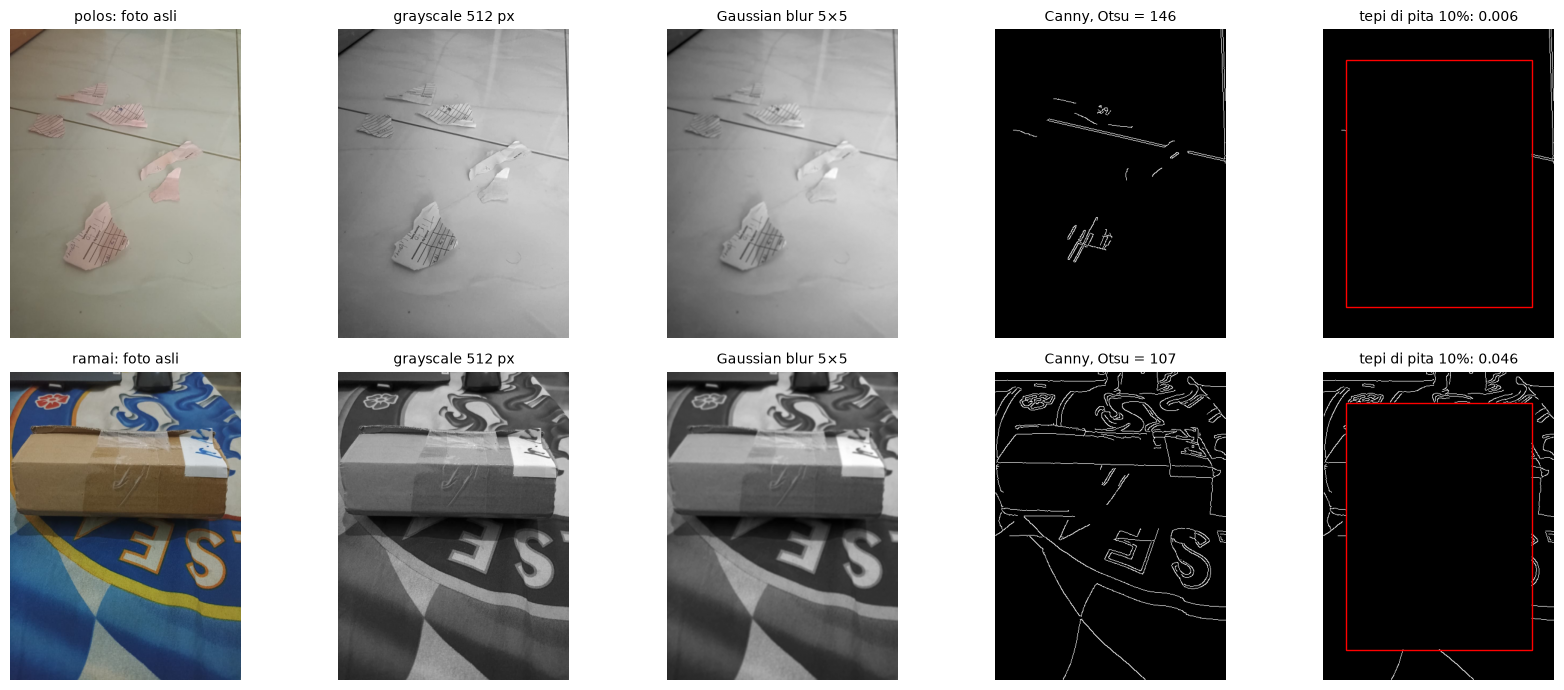

In [25]:
import matplotlib.pyplot as plt

labels = pd.read_csv(LABELS_CSV, dtype=str, keep_default_na=False)
rng = np.random.default_rng(SEED)
examples = {name: rng.choice(labels.loc[labels["background"] == name, "raw_path"].to_numpy()) for name in ("polos", "ramai")}

fig, axes = plt.subplots(2, 5, figsize=(17, 7))
for row, (name, raw_path) in zip(axes, examples.items()):
    steps = canny_steps(raw_path)
    height, width = steps["gray"].shape
    color = cv2.cvtColor(cv2.resize(steps["image"], (width, height), interpolation=cv2.INTER_AREA), cv2.COLOR_BGR2RGB)
    panels = [
        (color, f"{name}: foto asli"),
        (steps["gray"], "grayscale 512 px"),
        (steps["blurred"], "Gaussian blur 5×5"),
        (steps["edges"], f"Canny, Otsu = {steps['otsu']:.0f}"),
        (np.where(steps["band"], steps["edges"], 0), f"tepi di pita 10%: {edge_density(raw_path):.3f}"),
    ]
    for ax, (panel, title) in zip(row, panels):
        ax.imshow(panel, cmap=None if panel.ndim == 3 else "gray")
        ax.set_title(title, fontsize=10)
        ax.axis("off")
    dy, dx = round(height * BORDER), round(width * BORDER)
    row[-1].add_patch(plt.Rectangle((dx, dy), width - 2 * dx, height - 2 * dy, fill=False, edgecolor="red"))

fig.tight_layout()
fig.savefig(REPORTS_DIR / "dataset" / "background_canny_steps.png", dpi=150, bbox_inches="tight")

In [26]:
scores = labels.assign(score=labels["raw_path"].map(edge_density))
scores = scores.merge(photos[["raw_path", "object_id", "label", "view"]], on="raw_path")
scores = scores[scores["background"] != "ragu"].sort_values("score").reset_index(drop=True)

scores.groupby("background")["score"].describe().round(3)

,count,mean,std,min,25%,50%,75%,max
background,,,,,,,,
polos,26.0,0.024,0.061,0.000,0.001,0.008,0.015,0.311
ramai,14.0,0.032,0.029,0.002,0.010,0.030,0.043,0.113


In [27]:
from sklearn.metrics import roc_auc_score

is_ramai = scores["background"] == "ramai"
auc = roc_auc_score(is_ramai, scores["score"])

ramai_scores = scores.loc[is_ramai, "score"].to_numpy()
polos_scores = scores.loc[~is_ramai, "score"].to_numpy()
differences = ramai_scores[:, None] - polos_scores[None, :]
pair_auc = ((differences > 0).sum() + 0.5 * (differences == 0).sum()) / differences.size

print(f"pasangan ramai-polos: {differences.size} ({len(ramai_scores)} x {len(polos_scores)})")
print(f"pasangan dengan skor ramai lebih tinggi: {(differences > 0).sum()}")
print(f"AUC dihitung dari pasangan: {pair_auc:.3f}")
print(f"AUC dari scikit-learn: {auc:.3f}")

pasangan ramai-polos: 364 (14 x 26)
pasangan dengan skor ramai lebih tinggi: 262
AUC dihitung dari pasangan: 0.720
AUC dari scikit-learn: 0.720


ambang terbaik: skor >= 0.024 dianggap ramai
agreement: 75.0% (30 dari 40 foto)
pembanding, semua ditebak polos: 65.0%


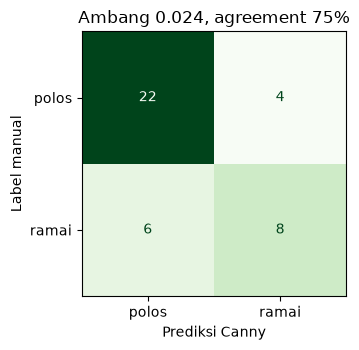

In [28]:
from sklearn.metrics import ConfusionMatrixDisplay

candidates = np.unique(scores["score"])
agreements = [((scores["score"] >= threshold) == is_ramai).mean() for threshold in candidates]
best_threshold = candidates[int(np.argmax(agreements))]
predicted = pd.Series(np.where(scores["score"] >= best_threshold, "ramai", "polos"), name="prediksi Canny")
agreement = (predicted == scores["background"]).mean()
baseline = (~is_ramai).mean()

print(f"ambang terbaik: skor >= {best_threshold:.3f} dianggap ramai")
print(f"agreement: {agreement:.1%} ({(predicted == scores['background']).sum()} dari {len(scores)} foto)")
print(f"pembanding, semua ditebak polos: {baseline:.1%}")
fig, ax = plt.subplots(figsize=(4, 3.6))
ConfusionMatrixDisplay.from_predictions(
    scores["background"], predicted, labels=["polos", "ramai"], cmap="Greens", colorbar=False, ax=ax
)
ax.set_xlabel("Prediksi Canny")
ax.set_ylabel("Label manual")
ax.set_title(f"Ambang {best_threshold:.3f}, agreement {agreement:.0%}")
fig.tight_layout()
fig.savefig(REPORTS_DIR / "dataset" / "background_canny_confusion.png", dpi=150)

pada ambang 0.024: TPR = 57%, FPR = 15%


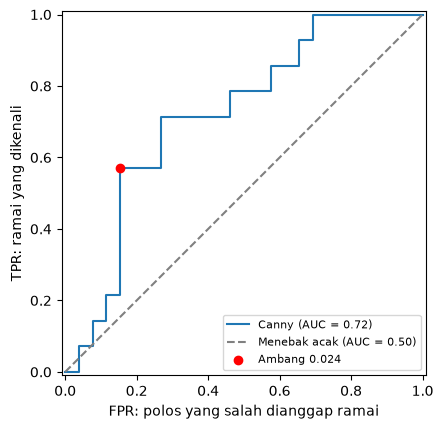

In [29]:
from sklearn.metrics import RocCurveDisplay

predicted_ramai = predicted == "ramai"
tpr = (predicted_ramai & is_ramai).sum() / is_ramai.sum()
fpr = (predicted_ramai & ~is_ramai).sum() / (~is_ramai).sum()
print(f"pada ambang {best_threshold:.3f}: TPR = {tpr:.0%}, FPR = {fpr:.0%}")

fig, ax = plt.subplots(figsize=(4.6, 4.4))
RocCurveDisplay.from_predictions(is_ramai, scores["score"], name="Canny", ax=ax)
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Menebak acak (AUC = 0.50)")
ax.scatter(fpr, tpr, color="red", zorder=3, label=f"Ambang {best_threshold:.3f}")
ax.set_xlabel("FPR: polos yang salah dianggap ramai")
ax.set_ylabel("TPR: ramai yang dikenali")
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
fig.savefig(REPORTS_DIR / "dataset" / "background_canny_roc.png", dpi=150)

Lembar berikut mengurutkan 40 foto dari skor terendah (kiri atas) ke tertinggi (kanan bawah). Bingkai menunjukkan label manual dan kotak di pojok kanan atas menunjukkan prediksi Canny pada ambang terbaik. Hijau berarti polos, merah berarti ramai. Foto yang warna bingkai dan kotaknya berbeda adalah kesalahan Canny.

In [30]:
LABEL_COLORS = {"polos": (60, 170, 60), "ramai": (40, 40, 220)}


def scored_tile(row, prediction: str) -> np.ndarray:
    """Thumbnail dengan bingkai warna label manual, kotak warna prediksi Canny, dan skor."""
    tile = cv2.resize(thumbnail(row.raw_path, row.no), (240, 240), interpolation=cv2.INTER_AREA)
    tile = cv2.copyMakeBorder(tile, 10, 10, 10, 10, cv2.BORDER_CONSTANT, value=LABEL_COLORS[row.background])
    height, width = tile.shape[:2]
    cv2.rectangle(tile, (width - 50, 0), (width, 50), LABEL_COLORS[prediction], -1)
    cv2.rectangle(tile, (0, height - 34), (120, height), (255, 255, 255), -1)
    cv2.putText(tile, f"{row.score:.3f}", (6, height - 9), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 0), 2)
    return tile


def legend_bar(width: int) -> np.ndarray:
    """Baris keterangan warna, kotak pojok, dan angka di atas lembar foto."""
    bar = np.full((110, width, 3), 255, np.uint8)
    font, black = cv2.FONT_HERSHEY_SIMPLEX, (0, 0, 0)
    x = 20
    for name, color in LABEL_COLORS.items():
        cv2.rectangle(bar, (x, 15), (x + 30, 45), color, -1)
        cv2.putText(bar, name, (x + 40, 40), font, 0.8, black, 2)
        x += 180
    cv2.putText(bar, "Bingkai = label manual   |   Kotak pojok kanan atas = prediksi Canny "
                f"(ambang {best_threshold:.3f})", (x + 20, 40), font, 0.8, black, 2)
    cv2.putText(bar, "Angka kiri atas = nomor foto   |   Angka kiri bawah = skor Canny (0-1)   |   "
                "Urutan: skor terendah (kiri atas) ke tertinggi (kanan bawah)", (20, 90), font, 0.8, black, 2)
    return bar


tiles = [scored_tile(row, prediction) for row, prediction in zip(scores.itertuples(), predicted)]
sheet = contact_sheet(tiles, 10)
sheet = np.vstack([legend_bar(sheet.shape[1]), sheet])
path = REPORTS_DIR / "dataset" / "background_canny_sorted.png"
path.write_bytes(cv2.imencode(".png", sheet)[1].tobytes())
print("disimpan:", path.relative_to(ROOT))

disimpan: reports\dataset\background_canny_sorted.png


In [31]:
comparison = scores.assign(prediction=predicted, match=predicted == scores["background"])
print(f"cocok: {comparison['match'].sum()} dari {len(comparison)} foto")

comparison = comparison[["no", "object_id", "label", "view", "background", "prediction", "match", "score"]]
comparison = comparison.assign(match=comparison["match"].map({True: "ya", False: "tidak"})).rename(
    columns={"background": "label manual", "prediction": "prediksi Canny", "match": "cocok"}
)
comparison.round({"score": 3})

cocok: 30 dari 40 foto


,no,object_id,label,view,label manual,prediksi Canny,cocok,score
0,8,KD-M-004,kardus,atas,polos,polos,ya,0.000
1,11,KT-F-009,kertas,atas,polos,polos,ya,0.000
2,38,KT-J-012,kertas,atas,polos,polos,ya,0.000
3,35,KT-M-002,kertas,atas,polos,polos,ya,0.000
4,34,KT-F-005,kertas,miring,polos,polos,ya,0.000
5,19,PL-M-007,plastik,atas,polos,polos,ya,0.000
6,1,KT-M-002,kertas,miring,polos,polos,ya,0.000
7,39,KD-M-004,kardus,miring,polos,polos,ya,0.002
8,13,PL-J-006,plastik,miring,ramai,polos,tidak,0.002
9,2,KT-J-011,kertas,atas,polos,polos,ya,0.002


## Kesimpulan

Edge density Canny di pita pinggir menghasilkan AUC 0,720 terhadap label manual. Pada ambang terbaik (skor 0,024), kecocokannya 75% atau 30 dari 40 foto, hanya 10 poin di atas tebakan "semua polos" (65%). Angka 75% ini juga masih optimis karena ambangnya dipilih dari foto yang sama. Kedua hasil berada di bawah kriteria yang ditetapkan sebelum pengujian (AUC ≥ 0,90 dan agreement ≥ 85%), sehingga Canny tidak dipakai untuk mengukur latar.

Kesalahannya membentuk dua pola. Latar polos yang bertekstur rapat, seperti karpet berbintik, lantai teraso, dan serat kayu yang kontras, mendapat skor tinggi (no. 18, 25, 10, 30). Sebaliknya, latar ramai yang terdiri dari permukaan mulus, seperti lantai dan dinding atau meja dan dinding, serta benda yang buram, mendapat skor rendah (no. 13, 22, 7, 6, 23, 36). Penyebabnya, Canny mengukur banyaknya tepi tajam, sedangkan label mengukur apakah latar seragam atau tidak. Dua hal ini berkaitan tetapi tidak sama.

Kekhawatiran awal bahwa garis nat keramik akan terhitung sebagai latar ramai tidak terbukti. Semua foto lantai keramik berlabel polos mendapat skor rendah karena kontras garis natnya tidak lolos ambang Canny.

Keputusan: latar dilabeli manual per foto mengikuti `docs/panduan-label-latar.md`.